# TCB — UV-vis & XRD analysis

Imports and plots the raw data in this folder:

| Technique | File | Content |
|---|---|---|
| UV-vis diffuse reflectance | `UV-vis/2026 09 24 %R.csv` (export of the `.DSW`) | `%R` vs wavelength, 2500 → 200 nm |
| XRD (Bruker D8, powder) | `XRay/MG_AS.brml` (a zip container; `MG_AS.zip` is an identical copy) | intensity vs 2θ, 20–80° |

Uses the repo's **pixi** environment (numpy + matplotlib, no pandas needed).


In [1]:
from pathlib import Path
import zipfile
import xml.etree.ElementTree as ET

import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path.cwd()
UVVIS_DIR = DATA_DIR / "UV-vis"
XRAY_DIR = DATA_DIR / "XRay"
XRAY_DIR2 = DATA_DIR / "Xray2"

plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
print("Data dir:", DATA_DIR)


Data dir: /Users/rifusaki/localRepos/uni/tcb


## 1. UV-vis diffuse reflectance

The CSV starts with a sample-name line, then a header row, so we skip the first two lines.

In [2]:
uvvis_csv = sorted(UVVIS_DIR.glob("*.csv"))[0]
lines = uvvis_csv.read_text(errors="ignore").splitlines()
sample_name = ",".join(p.strip() for p in lines[0].split(",") if p.strip()) or uvvis_csv.stem

wl, refl = [], []
for line in lines[2:]:
    parts = line.split(",")
    if len(parts) >= 2 and parts[0].strip() and parts[1].strip():
        wl.append(float(parts[0]))
        refl.append(float(parts[1]))

wl = np.asarray(wl)
refl = np.asarray(refl)
order = np.argsort(wl)
wl, refl = wl[order], refl[order]

print(f"Sample: {sample_name}")
print(f"{wl.size} points, {wl.min():.0f}–{wl.max():.0f} nm")
print(f"%R range: {refl.min():.2f} … {refl.max():.2f} (mean {refl.mean():.2f})")


Sample: MgFe2O4
2301 points, 200–2500 nm
%R range: -26.16 … 116.54 (mean 25.83)


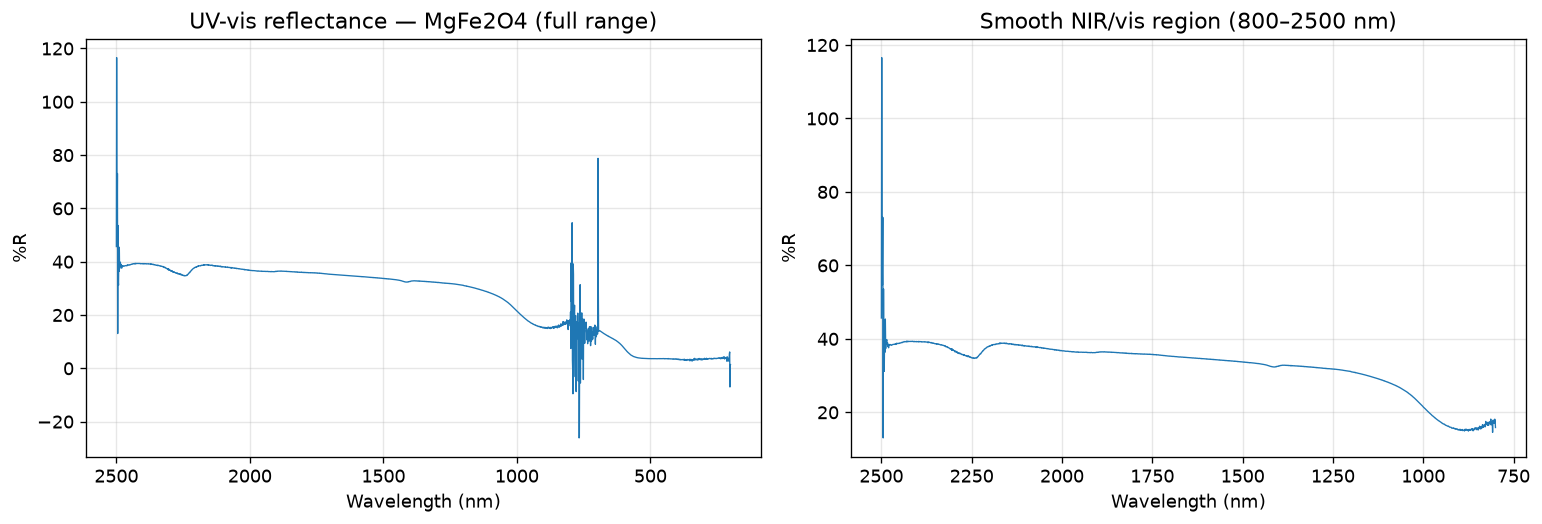

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.plot(wl, refl, lw=0.8, color="C0")
ax.set_title(f"UV-vis reflectance — {sample_name} (full range)")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("%R")
ax.invert_xaxis()

ax = axes[1]
smooth = wl >= 800
ax.plot(wl[smooth], refl[smooth], lw=0.8, color="C0")
ax.set_title("Smooth NIR/vis region (800–2500 nm)")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("%R")
ax.invert_xaxis()

fig.tight_layout()
plt.show()


The 200–800 nm region is dominated by detector/lamp noise (large point-to-point scatter, occasional negative values), so it is shown separately below rather than mixed into the smooth region.

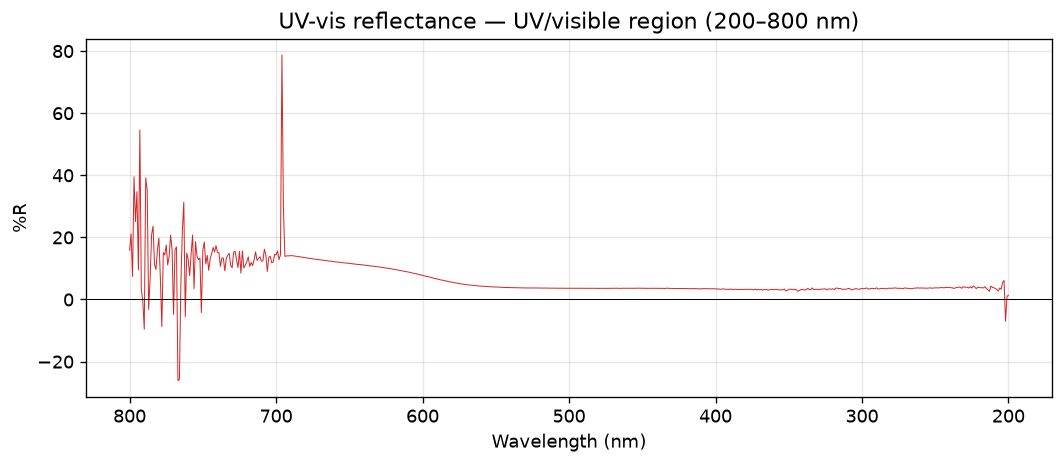

In [4]:
noisy = wl <= 800

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(wl[noisy], refl[noisy], lw=0.6, color="C3")
ax.axhline(0, color="k", lw=0.6)
ax.set_title("UV-vis reflectance — UV/visible region (200–800 nm)")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("%R")
ax.invert_xaxis()
fig.tight_layout()
plt.show()


## 2. XRD — powder diffraction (Bruker D8)

`MG_AS.brml` is a zip archive. The measured `Datum` rows in `Experiment0/RawData0.xml` have the form
`time_per_step, flag, 2θ, θ, intensity`.

In [7]:
brml_path = XRAY_DIR / "MG_AS.brml"

with zipfile.ZipFile(brml_path) as zf:
    raw_xml = zf.read("Experiment0/RawData0.xml")

brml_path2 = XRAY_DIR2 / "MgFeO4.brml"
with zipfile.ZipFile(brml_path2) as zf:
    raw_xml2 = zf.read("Experiment0/RawData0.xml")

root = ET.fromstring(raw_xml)
data = np.array([[float(v) for v in d.text.split(",")] for d in root.iter("Datum")])
two_theta = data[:, 2]
intensity = data[:, 4]

scan = root.find(".//ScanInformation")
print(f"{two_theta.size} points | 2θ = {scan.findtext('ScanAxes/ScanAxisInfo/Start')} – "
      f"{float(scan.findtext('ScanAxes/ScanAxisInfo/Stop')):.3f}° | "
      f"step ≈ {float(scan.findtext('ScanAxes/ScanAxisInfo/Increment')):.4f}° | "
      f"{scan.findtext('ScanModeVisibleName')}")


root2 = ET.fromstring(raw_xml2)
data2 = np.array([[float(v) for v in d.text.split(",")] for d in root.iter("Datum")])
two_theta2 = data[:, 2]
intensity2 = data[:, 4]

scan2 = root2.find(".//ScanInformation")
print(f"{two_theta2.size} points | 2θ = {scan2.findtext('ScanAxes/ScanAxisInfo/Start')} – "
      f"{float(scan2.findtext('ScanAxes/ScanAxisInfo/Stop')):.3f}° | "
      f"step ≈ {float(scan2.findtext('ScanAxes/ScanAxisInfo/Increment')):.4f}° | "
      f"{scan2.findtext('ScanModeVisibleName')}")


2015 points | 2θ = 20 – 79.993° | step ≈ 0.0298° | Continuous PSD fast
2015 points | 2θ = 10 – 74.997° | step ≈ 0.0298° | Continuous PSD fast


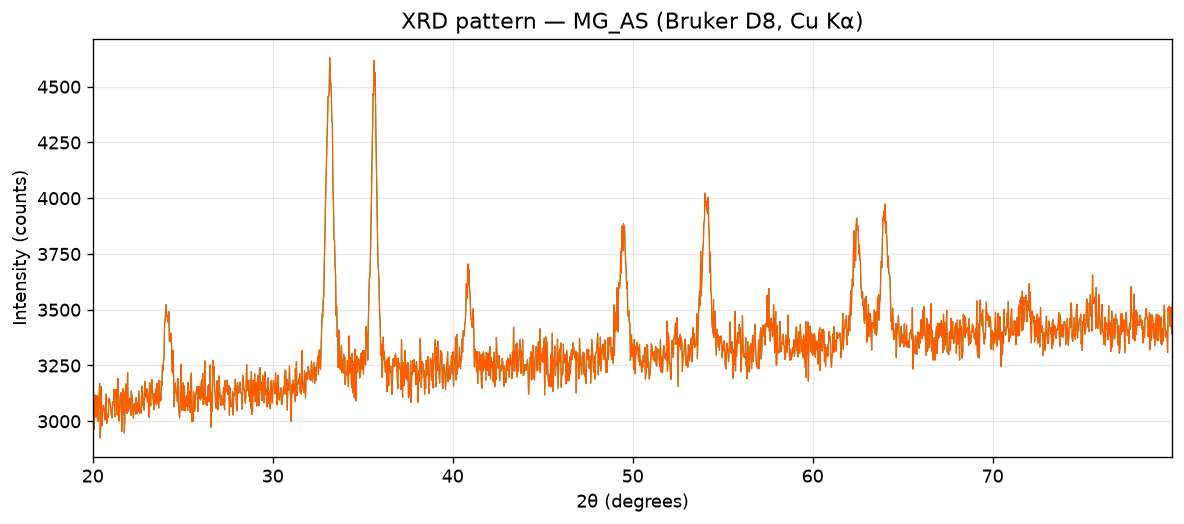

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(two_theta, intensity, lw=0.7, color="C2")
ax.plot(two_theta2, intensity2, lw=0.7, color="xkcd:bright orange")
ax.set_title("XRD pattern — MG_AS (Bruker D8, Cu Kα)")
ax.set_xlabel("2θ (degrees)")
ax.set_ylabel("Intensity (counts)")
ax.set_xlim(two_theta.min(), two_theta.max())
fig.tight_layout()
plt.show()


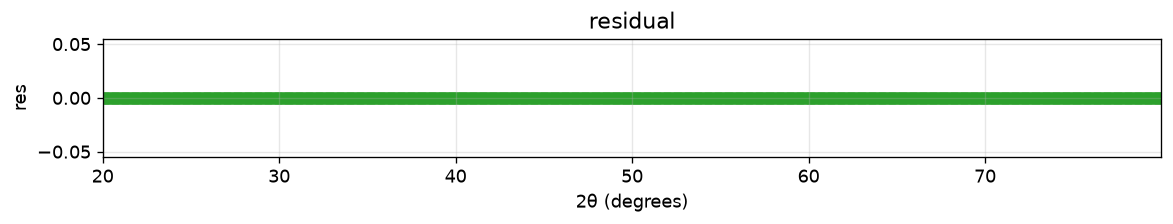

In [14]:
res = intensity2 - intensity

fig, ax = plt.subplots(figsize=(10, 2))
ax.scatter(two_theta, res, label=".", color="C2")
ax.set_title("residual")
ax.set_xlabel("2θ (degrees)")
ax.set_ylabel("res")
ax.set_xlim(two_theta.min(), two_theta.max())
fig.tight_layout()
plt.show()

## Notes

- `UV-vis/2026 09 24 %R.DSW` is the native Shimadzu binary; the notebook uses its CSV export.
- `MG_AS.zip` is a byte-identical copy of `MG_AS.brml`; `XRay/MG_AS/` is its extracted contents.

## 3. Rietveld refinement (XRD, both scans)

Two-phase Rietveld-style refinement of **both** Bruker D8 scans:

| Scan | File | Range |
|---|---|---|
| `MG_AS` | `XRay/MG_AS.brml` | 20–80° 2θ |
| `MgFeO4` | `Xray2/MgFeO4.brml` | 10–75° 2θ |

**Model.** Phases: hematite (α-Fe₂O₃, R-3c) and magnesioferrite (MgFe₂O₄, Fd-3m **inverse** spinel: Fe on tetrahedral 8a, Mg/Fe disordered on octahedral 16d). Pseudo-Voigt peaks with Thompson–Cox–Hastings Cu Kα₁/Kα₂ doublets, Caglioti FWHM(2θ), Chebyshev background (6 terms), per-phase lattice parameters and a zero shift. Phase scales and background are solved by weighted linear least squares inside each nonlinear step (variable projection), with scales constrained non-negative. Reflection tables (hkl + relative intensities from pymatgen for the ideal structures) live in `rietveld/reflections.json`; the refinement code in `rietveld/rietveld_tcb.py` needs only numpy/scipy/matplotlib.

The directory also contains exports for external Rietveld software (X'Pert HighScore Plus, EVA, GSAS-II, ...): plain `.xy` intensity files and starting-model CIFs.

In [7]:
import sys
sys.path.insert(0, str(DATA_DIR / "rietveld"))

from rietveld_tcb import refine_pattern, plot

fits = {}
for tag, rel in [("MG_AS", "XRay/MG_AS.brml"), ("MgFeO4", "Xray2/MgFeO4.brml")]:
    fits[tag] = refine_pattern(tag, DATA_DIR / rel)

== MG_AS: phases = hematite, spinel
Rwp = 1.78%
  Hematite (alpha-Fe2O3)       a = 5.0381 A, c = 13.7623 A
  Magnesioferrite (MgFe2O4, inverse spinel) a = 8.3600 A
  wt% Hematite (alpha-Fe2O3)            100.0
  wt% Magnesioferrite (MgFe2O4, inverse spinel)   0.0
  zero shift = -0.001 deg | Caglioti U = 0.203, V = -0.000, W = 0.1500 | eta = 0.43+0.24*2th/100


== MgFeO4: phases = hematite, spinel
Rwp = 1.85%
  Hematite (alpha-Fe2O3)       a = 5.0356 A, c = 13.7440 A
  Magnesioferrite (MgFe2O4, inverse spinel) a = 8.3743 A
  wt% Hematite (alpha-Fe2O3)             96.7
  wt% Magnesioferrite (MgFe2O4, inverse spinel)   3.3
  zero shift = -0.023 deg | Caglioti U = 0.006, V = -0.000, W = 0.0415 | eta = 0.53+0.30*2th/100


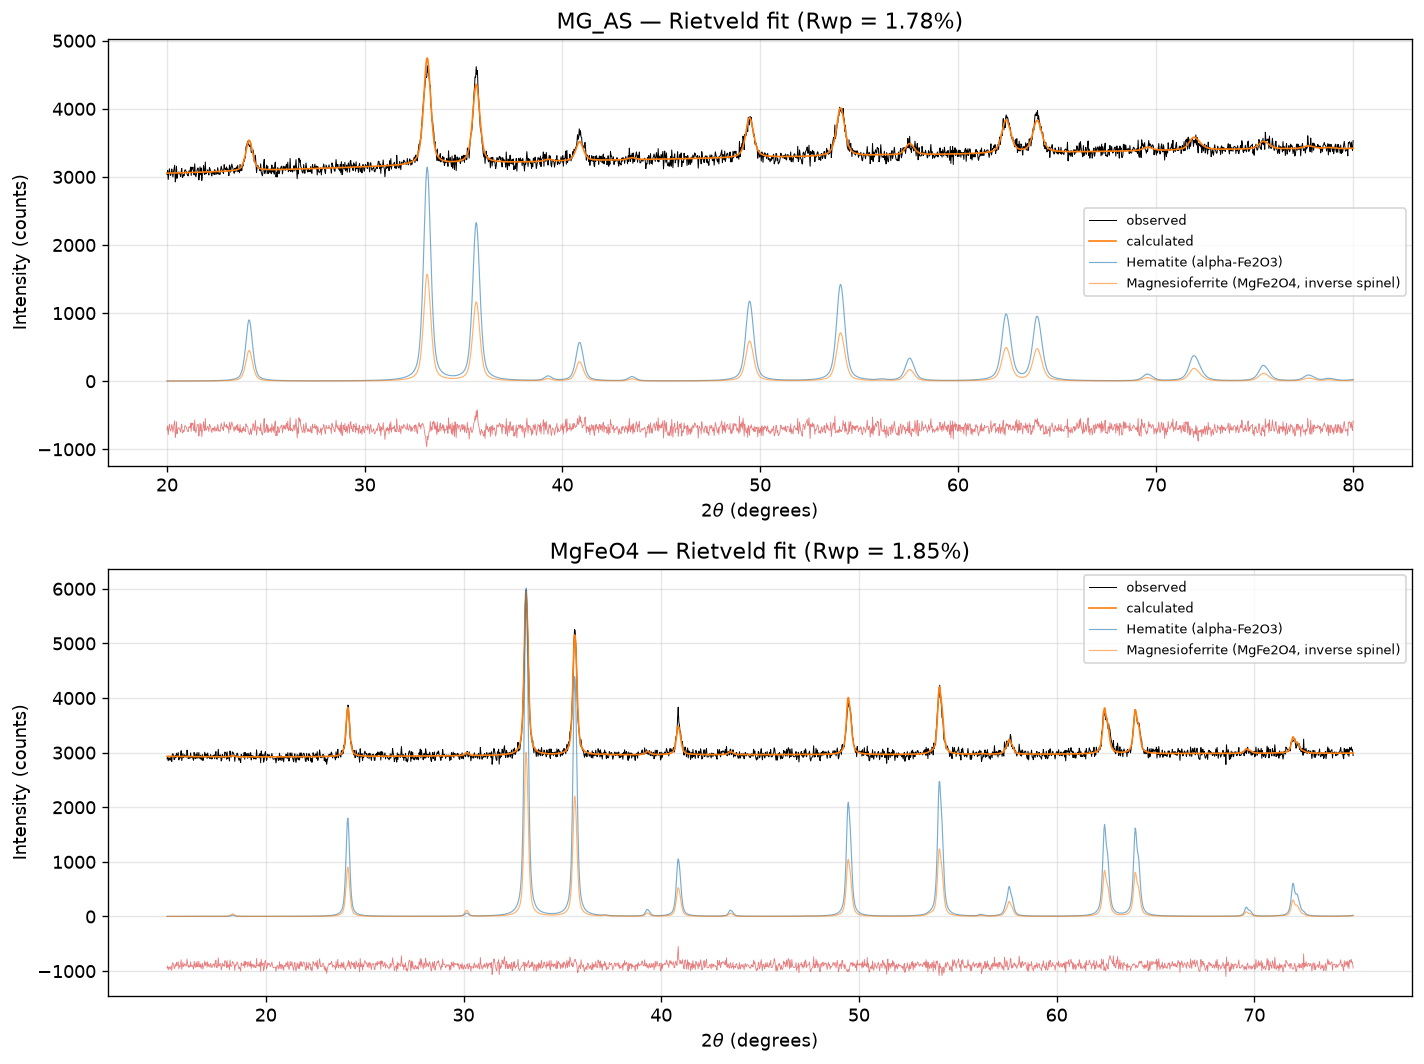

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=False)
for ax, (tag, R) in zip(axes, fits.items()):
    plot(R, tag, ax)
fig.tight_layout()
plt.show()

### Results

| | MG_AS | MgFeO4 |
|---|---|---|
| Rwp | 1.78% | 1.85% |
| Hematite a (Å) | 5.038 | 5.036 |
| Hematite c (Å) | 13.762 | 13.744 |
| Spinel a (Å) | 8.360* | 8.374 |
| Hematite (wt%) | ~100 | ~97 |
| MgFe₂O₄ spinel (wt%) | ~0 (below detection) | ~3 |

* MG_AS: the spinel refines to a scale statistically indistinguishable from zero —
  any MgFe₂O₄ present is below the detection limit of this scan.

Both scans are **dominated by α-Fe₂O₃ (hematite)**. For MgFeO4 the MgFe₂O₄ spinel
is a minor phase (~3 wt%); periclase (MgO) refines to ≈0 wt% in both. Given the
weak spinel reflections (net intensities of a few hundred counts on a
~3000-count background), the spinel weight fraction carries a large uncertainty
(order ±50% relative); the hematite lattice parameters and phase dominance are
robust.

Caveats: no instrument standard (LaB₆) was measured, so the Caglioti profile
terms mix instrument and sample broadening — treat size/strain information as
qualitative only. Refining the spinel O positional parameter `u` or the cation
distribution is not warranted at this data quality.

**Exports for X'Pert HighScore / EVA / GSAS-II** (in `tcb/rietveld/`):
`MG_AS.xy`, `MgFeO4.xy` (2θ / counts) and the starting-model CIFs
`hematite_Fe2O3.cif`, `spinel_MgFe2O4.cif`.